#                                          Introduction of Tree Pruning.
```js
        Cutting off branches or leaves of a tree. max_depth = None means we’re building the whole tree on the training dataset and the decision tree model learns everything about data thoroughly which is why it underperforms on testing dataset, OVERFITTING.

        To reduce this overfitting, so the model can perform maximum best on testing data, we do pruning on the decision tree during training by setting max_depth an integer value, limiting the features etc.

        There are 2 types of tree pruning :
            1) Post Pruning (or Cost Complexity Pruning) : Here at first the tree is built completely and then the unnecessary branches get removed|pruned using the Cost Complexity Pruning method.

            2) Pre Pruning : Pre-pruning (also known as early stopping) restricts the growth of the tree 'during training', preventing it 'from reaching its maximum depth and potentially overfitting'. So it stops growing the tree during training when splitting a node no longer improves the model meaningfully.
```

#                                               1) Post-Pruning (or Cost Complexity Pruning)
```js
        Read the whole theory from scratch in "Post Pruning (or Cost Complexity Pruning).pdf" in Theory folder.
```

In [22]:
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree

import pandas as pd
import matplotlib.pyplot as plt

#                                                ----- Dataset imports and splits

In [2]:
pd.set_option('display.max_columns', 32) # since we've 32 columns in the below dataset.
pd.set_option('display.width', 1366)

df = pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\6. Decision Tree\Dataset\breast_cancer.csv").iloc[:, 1:]

print(df.head(5), '\n\n')
print(df.info()) # No Null values.

X, y = df.iloc[:, :-1], df.iloc[:, -1]
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  compactness_mean  concavity_mean  concave points_mean  symmetry_mean  fractal_dimension_mean  radius_se  texture_se  perimeter_se  area_se  smoothness_se  compactness_se  concavity_se  concave points_se  symmetry_se  fractal_dimension_se  radius_worst  texture_worst  perimeter_worst  area_worst  smoothness_worst  compactness_worst  concavity_worst  concave points_worst  symmetry_worst  fractal_dimension_worst  detected
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871     1.0950      0.9053         8.589   153.40       0.006399         0.04904       0.05373            0.01587      0.03003              0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119                0.2654          0.4601                  0.11890         0
1     

#                                       ----- Creating a Fully Grown Decision Tree

Accuracy on training dataset = 1.0.
Accuracy on testing  dataset = 0.9473684210526315.


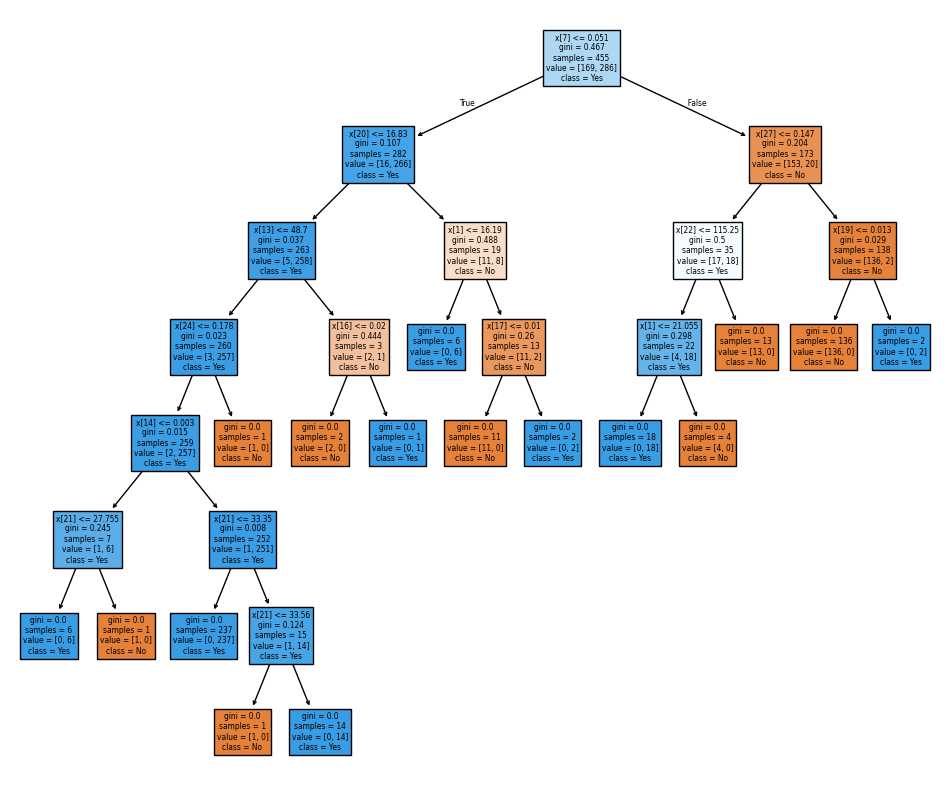

In [3]:
tree = DecisionTreeClassifier(max_depth = None, random_state = 42)
tree.fit(X = x_train, y = y_train)

print(f"Accuracy on training dataset = {tree.score(X = x_train, y = y_train)}.")
print(f"Accuracy on testing  dataset = {tree.score(X = x_test,  y = y_test)}.")

plt.figure(figsize = (12, 10))
plot_tree(decision_tree = tree,
          # feature_names = x_train.columns,
          class_names = ['No', 'Yes'], # as in ['Not detected', 'detected'] == [0, 1].
          filled = True)
plt.show()

#                            ----- Finding the best CCP_ALPHA value to get the highest accuracy on testing.

In [4]:
path = tree.cost_complexity_pruning_path(X = x_train, y = y_train)
ccps = path.ccp_alphas # Each value represents the ccp_value for each subtree.
print(ccps)

best_ccp, old_max_accuracy = None, -1
for ccp in ccps:
    cur_tree_accuracy = ( DecisionTreeClassifier(max_depth = None, ccp_alpha = ccp, random_state = 42)
                         .fit(X = x_train, y = y_train)
                         .score(X = x_test, y = y_test) ) # this score and accuracy_score is exactly the same.
    if cur_tree_accuracy > old_max_accuracy:
        best_ccp, old_max_accuracy = ccp, cur_tree_accuracy

print(f"Best ccp_alpha value = {best_ccp} for what the highest accuracy on testing = {old_max_accuracy}.")

[0.         0.00218083 0.0029304  0.00431133 0.00559513 0.00743872
 0.0086638  0.01291987 0.01438561 0.02404453 0.02442056 0.0306549
 0.3228506 ]
Best ccp_alpha value = 0.004311334641004935 for what the highest accuracy on testing = 0.956140350877193.


#                                   ----- Creating Tree with best CCP_ALPHA value.

Accuracy on training dataset = 0.9912087912087912.
Accuracy on testing  dataset = 0.956140350877193.


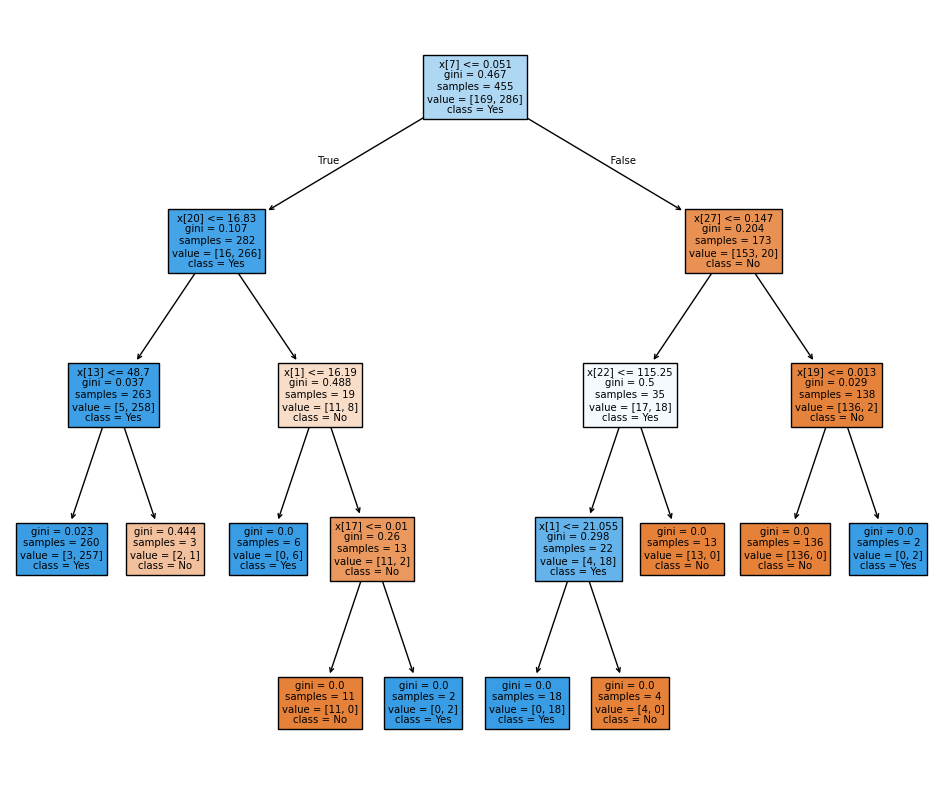

In [8]:
tree1 = DecisionTreeClassifier(max_depth = None, ccp_alpha = best_ccp, random_state = 42)
tree1.fit(X = x_train, y = y_train)

print(f"Accuracy on training dataset = {tree1.score(X = x_train, y = y_train)}.")
print(f"Accuracy on testing  dataset = {tree1.score(X = x_test,  y = y_test)}.")

plt.figure(figsize = (12, 10))
plot_tree(decision_tree = tree1,
          # feature_names = x_train.columns,
          class_names = ['No', 'Yes'], # as in ['Not detected', 'detected'] == [0, 1].
          filled = True)
plt.show()

explanation = """
In the section where we created the fully grown tree with 7 levels, the output :
    Accuracy on training dataset = 1.0.
    Accuracy on testing  dataset = 0.9473684210526315.

Here with just 4 levels we decreased the training accuracy by 0.0087 and increased the testing accuracy by 0.0087. So with
minimal changes in Training accuracy we got the best result in just 4 levels from 7. We pruned the 4th leftmost subtree here.
"""

#                                               2) Pre-Pruning
```js
        Read the whole theory from scratch in "Pre Pruning.pdf" in Theory folder MUST where I also explained how GridSearchCV works using Pre-pruning.
```

#                                                ----- Dataset imports and splits

In [13]:
pd.set_option('display.max_columns', 32) # since we've 32 columns in the below dataset.
pd.set_option('display.width', 1366)

df = pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\6. Decision Tree\Dataset\breast_cancer.csv").iloc[:, 1:]

print(df.head(5), '\n\n')
print(df.info()) # No Null values.

X, y = df.iloc[:, :-1], df.iloc[:, -1]
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  compactness_mean  concavity_mean  concave points_mean  symmetry_mean  fractal_dimension_mean  radius_se  texture_se  perimeter_se  area_se  smoothness_se  compactness_se  concavity_se  concave points_se  symmetry_se  fractal_dimension_se  radius_worst  texture_worst  perimeter_worst  area_worst  smoothness_worst  compactness_worst  concavity_worst  concave points_worst  symmetry_worst  fractal_dimension_worst  detected
0        17.99         10.38          122.80     1001.0          0.11840           0.27760          0.3001              0.14710         0.2419                 0.07871     1.0950      0.9053         8.589   153.40       0.006399         0.04904       0.05373            0.01587      0.03003              0.006193         25.38          17.33           184.60      2019.0            0.1622             0.6656           0.7119                0.2654          0.4601                  0.11890         0
1     

#                                    ----- Applying GridSearchCV to find the best hyperparameters values
```js
Use GridSearchCV when you have small dataset and parameters are not too much because GridSearchCV test each combination of hyperparameters and return the best one. But if you have time to train GridSearchCV as it takes a lot time if dataset is large, then use it.
```

In [14]:
parameters = {'criterion'         : ['gini', 'entropy', 'log_loss'],
              'max_depth'         : [5, 8, 15],
              'max_features'      : [5, 10],
              'min_samples_split' : [2, 6, 12, 18],
              'random_state'      : [42, 50, 60]
             } # 3 * 3 * 2 * 4 * 3 = 216 unique trees.

search = GridSearchCV(estimator = DecisionTreeClassifier(),
                      param_grid = parameters,
                      cv = 5,
                      n_jobs = -1)

search.fit(X = X, y = y) # The main dataset, not training dataset since GridSearchCV creates training and testing dataset
                         # from its own which we discussed in the "Pre Pruning.pdf".
print(f"Best Accuracy Score = {search.best_score_}.")
print(f"\nBest Hyperparameters values : \n{search.best_params_}.")

Best Accuracy Score = 0.9525539512498058.

Best Hyperparameters values : 
{'criterion': 'gini', 'max_depth': 5, 'max_features': 10, 'min_samples_split': 6, 'random_state': 42}.


#                                 ----- Setting the best hyperparameter values (from GridSearchCV) in Decision Tree

In [21]:
tree2 = DecisionTreeClassifier(criterion = 'gini',
                               max_depth = 5,
                               max_features = 10,
                               min_samples_leaf = 6,
                               random_state = 42)

tree2.fit(X = x_train, y = y_train)

print(f"Accuracy = {tree2.score(X = x_test, y = y_test)}.") # Decision Tree has builtin accuracy_score method, score().

explanation = """
The accuracy score in GridSearchCV we quantified using cross-validation where the testing dataset was different in each fold
and we took the mean of all the folds. But here we're quantifing accuracy using only x_test dataset. That's why we're seeing
some difference in both accuracies but 0.9298245614035088 is the best tree2 can produce from all those hyperparameters
values we set in GridSearchCV.
"""

Accuracy = 0.9298245614035088.


#                                    ----- Applying RandomSearchCV to find the best hyperparameters values
```js
Use RandomizedSearchCV when you have large dataset and parameters are much and you don’t have much time to run to get the best hyperparameters value but need at least better, because RandomizedSearchCV randomly pick some combinations of hyperparameters and return the best one. But if you have time to train GridSearchCV as it takes a lot time if dataset is large, then use it.
```

In [24]:
parameters = {'criterion'         : ['gini', 'entropy', 'log_loss'],
              'max_depth'         : [5, 8, 15],
              'max_features'      : [5, 10],
              'min_samples_split' : [2, 6, 12, 18],
              'random_state'      : [42, 50, 60]
             } # 3 * 3 * 2 * 4 * 3 = 216 unique trees.

search1 = RandomizedSearchCV(estimator = DecisionTreeClassifier(),
                             param_distributions = parameters,
                             cv = 5,
                             n_jobs = -1)

search1.fit(X = X, y = y) # The main dataset, not training dataset since GridSearchCV creates training and testing dataset
                         # from its own which we discussed in the "Pre Pruning.pdf".
print(f"Best Accuracy Score = {search1.best_score_}.")
print(f"\nBest Hyperparameters values : \n{search1.best_params_}.")

Best Accuracy Score = 0.9420121099208197.

Best Hyperparameters values : 
{'random_state': 60, 'min_samples_split': 12, 'max_features': 10, 'max_depth': 8, 'criterion': 'log_loss'}.


#                          ----- Setting the best hyperparameter values (from RandomizedSearchCV) in Decision Tree

In [ ]:
tree3 = DecisionTreeClassifier(criterion = 'log_loss',
                               max_depth = 8,
                               max_features = 10,
                               min_samples_leaf = 12,
                               random_state = 60)

tree3.fit(X = x_train, y = y_train)

print(f"Accuracy = {tree3.score(X = x_test, y = y_test)}.") # Decision Tree has builtin accuracy_score method, score().

explanation = """
The accuracy score in RandomizedSearchCV we quantified using cross-validation where the testing dataset was different in each
fold and we took the mean of all the folds. But here we're quantifing accuracy using only x_test dataset. That's why we're
seeing some difference in both accuracies
"""

Accuracy = 0.9298245614035088.
